# **Basic Single-Cell RNA-seq Analysis with Scanpy**
In this notebook, we’ll go through the first steps of single-cell RNA-seq data analysis. Our main reference is [Single-cell best practices](https://www.sc-best-practices.org/preamble.html), and you can always look there for more details and advanced explanations.

This notebook was prepared in Fall 2025 for the Bioinformatics course in the Department of Computer Engineering at Sharif University of Technology.

# **1. Anndata**
Anndata is a Python package designed for efficiently handling annotated data matrices, both in memory and on disk([Virshup,2021](https://www.biorxiv.org/content/10.1101/2021.12.16.473007v1.full)).

Key features include:
* Sparse data support
* Lazy operations
* A PyTorch interface

# **1.2 Structure of the AnnData Object**
The AnnData object is fundamentally a container designed to hold a central data matrix (`.X`) and all related metadata for high-dimensional biological data.

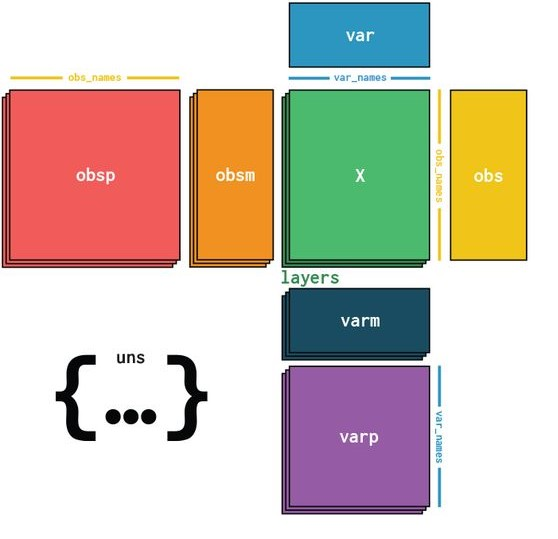

**Central Data (`.X`)**: This is the core matrix containing the actual measurements, such as gene expression levels, where rows are observations (e.g., cells) and columns are variables (e.g., genes).

**Annotations (`.obs` and `.var`)**: `.obs` stores metadata for the rows (observations), like cell type or patient ID. `.var` stores metadata for the columns (variables), like gene symbols or chromosome locations.

**Alternative Data Views (`.layers`)**: This slot holds alternative versions of the main data matrix `.X`, such as the raw counts, normalized counts, or scaled data.

**Multidimensional (`.obsm` and `.varm`)**: `.obsm` stores multi-dimensional data related to observations, primarily low-dimensional representations (like UMAP or PCA coordinates). `.varm` stores multi-dimensional data related to variables (e.g., gene embeddings).

**Pairwise (`.obsp` and `.varp`)**: `.obsp` stores pairwise relationships between observations, typically neighborhood graphs (cell-to-cell connections). `.varp` stores pairwise relationships between variables (e.g., gene-to-gene interactions).

**Unstructured (`.uns`)**: This is a dictionary used for storing miscellaneous, global metadata that doesn't fit into the structured slots, such as color maps, model parameters, or general experiment information.

# **1.3 AnnData provides broad interoperability with tools and platforms**
AnnData acts as a universal hub, facilitating the seamless flow of data from various external file formats (such as .csv, .tsv, .loom, and CellRanger output) into a structured in-memory and on-disk representation. Data stored in AnnData can be efficiently saved using specialized formats like .h5ad or .zarr. Crucially, AnnData provides the foundation for powerful Python APIs like Scanpy, Squidpy, and scvi-tools, and connects directly with machine learning frameworks like PyTorch and scikit-learn. Finally, the structured AnnData object serves as the standard input for sharing and interactive visualization using external applications and platforms such as CellxGene and R/TESSCE.


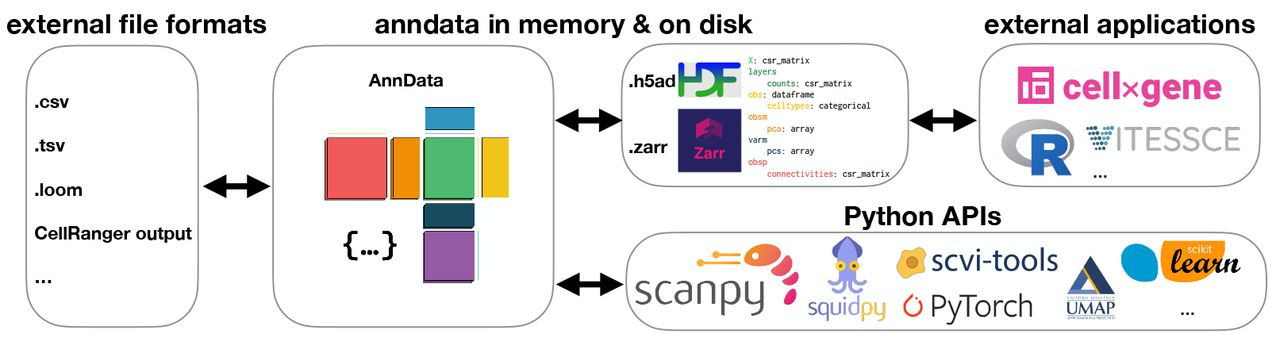

AnnData is available on PyPI and Conda can be installed with using either:

`pip install anndata`

`conda install -c conda-forge anndata`

# **2. Scanpy**
scanpy is a Python package which builds on top of AnnData to facilitate the analysis of single-cell gene expression data. Several methods for preprocessing, embedding, visualization, clustering, differential gene expression testing, pseudotime and trajectory inference, and simulation of gene regulatory networks are accessible through scanpy. The efficient implementation based on the Python data science and machine learning libraries allows scanpy to scale to millions of cells. 

# **2.1 Scanpy API design**
The scanpy framework is designed in a way that functions belonging to the same step are grouped in corresponding modules. For example, all preprocessing functions are available in the `scanpy.preprocessing` module, all transformation of a data matrix which are not preprocessing are available in `scanpy.tools` and all visualizations are available in `scanpy.plot`. These modules are commonly accessed after having imported scanpy like` import scanpy as sc` with the corresponding abbreviations` sc.pp` for preprocessing, `sc.tl` for tools and `sc.pl` for plots. All modules which read or write data are directly accessed. Further, a module for various datasets is available as `sc.datasets`. 
Readers are strongly encouraged to examine[ scanpy’s documentation](https://scanpy.readthedocs.io/en/stable/) for more details.

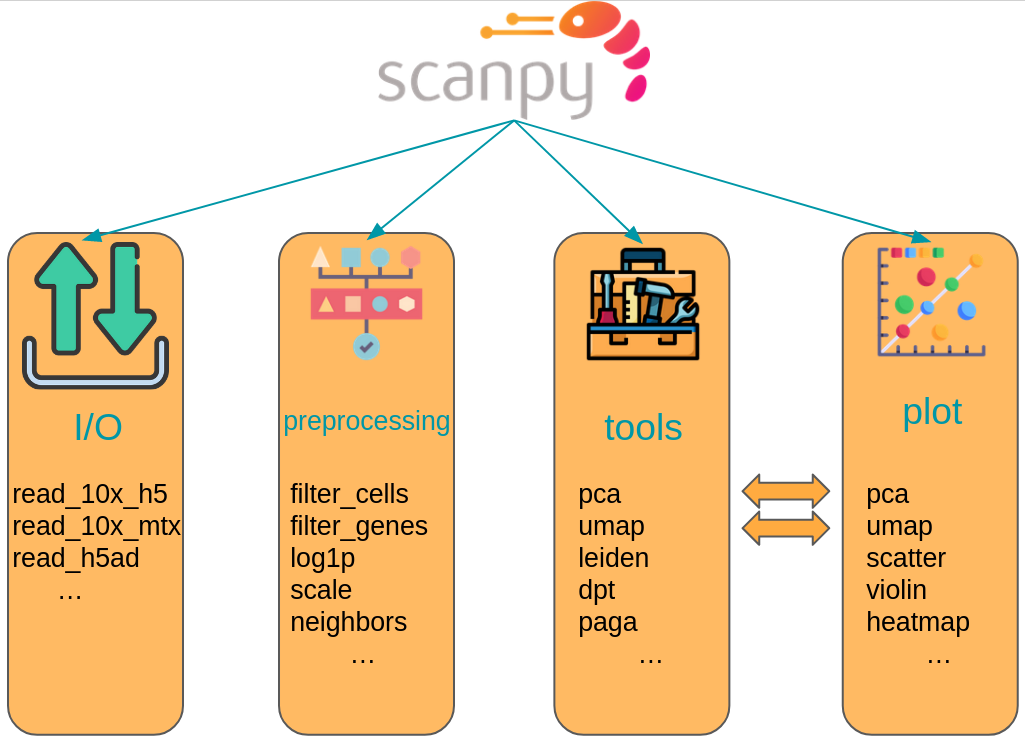

scanpy is available on PyPI and Conda can be installed with using either:

`pip install scanpy`

`conda install -c conda-forge scanpy`

# **3 Quality Control**
Single-cell RNA-seq datasets have two important properties that one should have in mind when performing an analysis. Firstly, scRNA-seq data is drop-out meaning that there is an excessive number of zeros in the data due to limiting mRNA. Secondly, the potential for correcting the data and performing quality control might be limited as the data may be confounded with biology. It is therefore crucial to select preprocessing methods that are suited to the underlying data without overcorrecting or removing biological effects.

Because of this, it is important to choose preprocessing methods that fit the data. The rapidly expanding set of tools for scRNA-seq includes steps such as doublet detection, quality control, normalization, feature selection, and dimensionality reduction. These choices strongly influence downstream analysis. If filtering is too strict, rare but meaningful cell populations may be lost. If filtering is too permissive, low-quality cells may remain and make annotation more difficult.

Therefore, it is essential to rely on well-established preprocessing tools, follow best practices, and be ready to re-evaluate preprocessing decisions, such as filtering strategies, based on downstream results.

# **3.1 Environment Setup and Data**
We use a 10x Multiome data set generated for a single-cell data integration challenge at the NeurIPS conference 2021 [[Luecken et al., 2021](https://openreview.net/forum?id=gN35BGa1Rt)]. This dataset captures single-cell multiomics data from bone marrow mononuclear cells of 12 healthy human donors measured at four different sites to obtain nested batch effects. In this tutorial, we will use one batch of the aforementioned dataset, sample 4 of donor 8, to showcase the best practices for scRNA-seq data preprocessing.

As a first step, we first load the dataset with scanpy which is hosted on figshare.

In [1]:
import numpy as np
import scanpy as sc
import seaborn as sns
from scipy.stats import median_abs_deviation

sc.settings.verbosity = 0
sc.set_figure_params(
    dpi=80,
    facecolor="white",
    frameon=False,
)

In [2]:
adata = sc.read_10x_h5(
    filename="filtered_feature_bc_matrix.h5",
    backup_url="https://figshare.com/ndownloader/files/39546196",
)
adata

/home/aneghabi/.local/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/aneghabi/.local/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


AnnData object with n_obs × n_vars = 16934 × 36601
    var: 'gene_ids', 'feature_types', 'genome', 'interval'

After reading the data, scanpy displays a warning that not all variable names are unique. This indicates that some variables (=genes) appear more than once which can lead to errors or unintended behavior for downstream analysis tasks. We execute the proposed function `var_names_make_unique()` which makes the variable name unique by appending a number string to each duplicate index element: ‘1’, ‘2’, etc.

In [3]:
adata.var_names_make_unique()
adata

AnnData object with n_obs × n_vars = 16934 × 36601
    var: 'gene_ids', 'feature_types', 'genome', 'interval'

The dataset has the shape `n_obs` 16,934 x `n_vars` 36,601. This translates into `barcodes x number of transcripts`. We additionally inspect further information in `.var` in terms of gene_ids (Ensembl Id), feature_types and genome.

# **3.2  Filtering Low Quality Cells**
Quality control (QC) begins by removing low-quality cells, which typically show low total counts, few detected genes, and a high fraction of mitochondrial reads, often indicating damaged or dying cells. QC thresholds are applied to three main covariates:

1. Total counts per cell

2. Number of detected genes

3. Fraction of mitochondrial reads

These covariates must be considered jointly, because biological variation can mimic QC issues. For example, a high mitochondrial fraction may reflect active respiration rather than poor quality, and unusually low or high counts may represent quiescent or large cell types. Therefore, QC should remain permissive to avoid removing real biological populations.

For small datasets, QC is often done manually; larger datasets benefit from automatic thresholding using MAD (median absolute deviation), defined as:

$$
MAD = \mathrm{median} \left( |X_i - \mathrm{median}(X)| \right)
$$

Cells differing by 5 MADs are flagged as outliers [[Germain et al., 2020](https://genomebiology.biomedcentral.com/articles/10.1186/s13059-020-02136-7)].

In QC, the first step is to calculate the QC covariates or metric. We compute these using the scanpy function sc.pp.calculate_qc_metrics, which can also calculate the proportions of counts for specific gene populations. We therefore define mitochondrial, ribosomal and hemoglobin genes. It is important to note that mitochondrial counts are annotated either with the prefix “mt-” or “MT-’’ depending on the species considered in the dataset. As mentioned, the dataset used in this notebook is human bone marrow, so mitochondrial counts are annotated with the prefix “MT-”. For mouse datasets, the prefix is usually lower case, so “mt-“.

In [4]:
# mitochondrial genes
adata.var["mt"] = adata.var_names.str.startswith("MT-")
# ribosomal genes
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))
# hemoglobin genes.
adata.var["hb"] = adata.var_names.str.contains("^HB[^(P)]")

We can now calculate the respective QC metrics with scanpy.

In [5]:
sc.pp.calculate_qc_metrics(
    adata, qc_vars=["mt", "ribo", "hb"], inplace=True, percent_top=[20], log1p=True
)
adata

/home/aneghabi/.local/lib/python3.10/site-packages/numba/np/ufunc/parallel.py:371: NumbaWarning: The TBB threading layer requires TBB version 2021 update 6 or later i.e., TBB_INTERFACE_VERSION >= 12060. Found TBB_INTERFACE_VERSION = 12050. The TBB threading layer is disabled.
  warnings.warn(problem)


AnnData object with n_obs × n_vars = 16934 × 36601
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'

As we can see, the function added a couple of additional columns to .var and .obs. We want to highlight a few of them here, more information on the different metrics can be found in the scanpy documentation:

- `n_genes_by_counts` is the number of genes with positive counts in a cell.
- `total_counts` is the total number of counts for a cell, also known as library size.
- `pct_counts_mt` is the proportion of total counts in a cell that are mitochondrial.

We now plot the three QC covariates `n_genes_by_counts`, `total_counts` and `pct_counts_mt` per sample to assess how well the respective cells were captured.

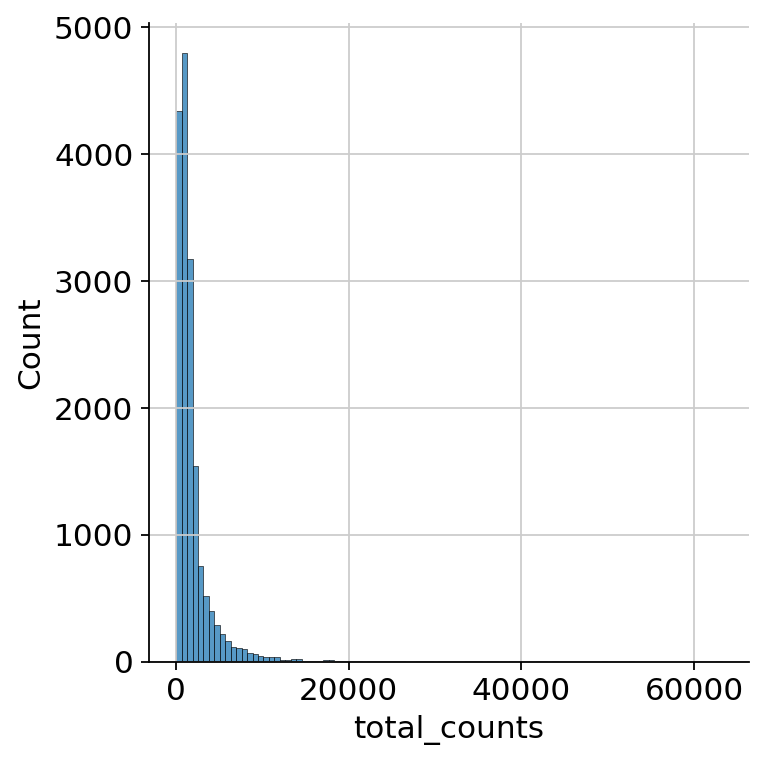

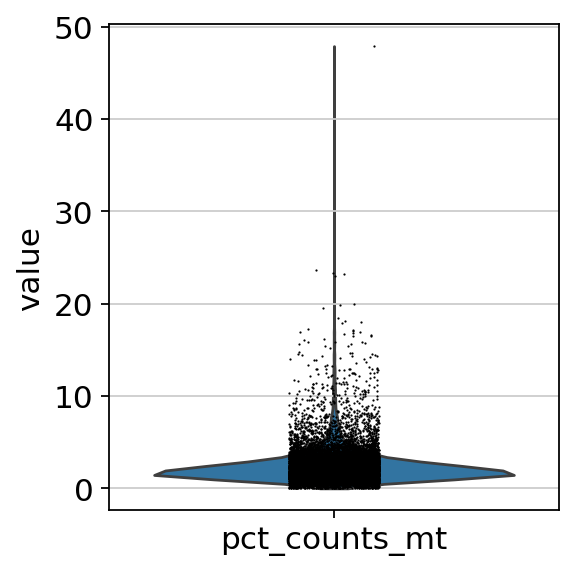

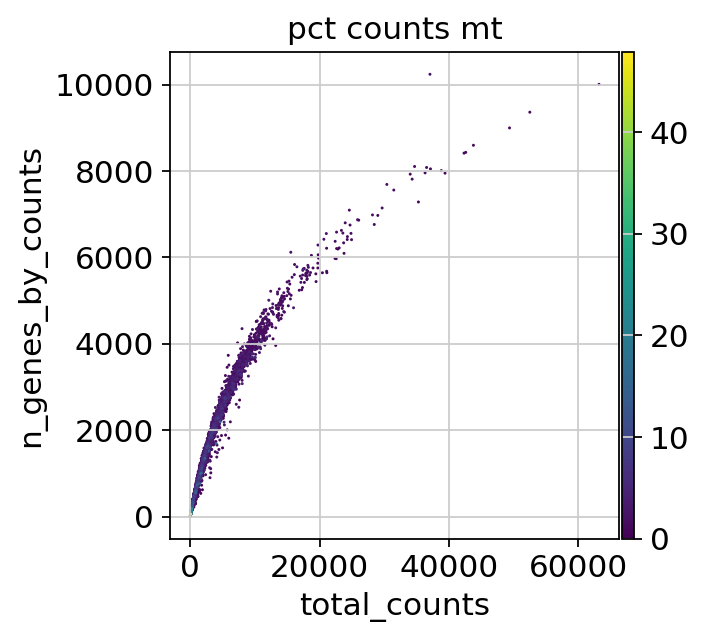

In [6]:
p1 = sns.displot(adata.obs["total_counts"], bins=100, kde=False)
# sc.pl.violin(adata, 'total_counts')
p2 = sc.pl.violin(adata, "pct_counts_mt")
p3 = sc.pl.scatter(adata, "total_counts", "n_genes_by_counts", color="pct_counts_mt")

The plots indicate that some cells have a relatively high percentage of mitochondrial counts which are often associated with cell degradation. But since number of counts per cell is sufficiently high and percentage of mitochondrial reads is for most cells below 20 % we can still process the data. Based on these plots, one could now also define manual thresholds for filtering cells. Instead, we will show QC with automatic thresholding and filtering based on MAD.

First, we define a function that takes a `metric`, i.e. a column in `.obs` and the number of MADs (`nmad`) that is still permissive within the filtering strategy.

In [7]:
def is_outlier(adata, metric: str, nmads: int):
    M = adata.obs[metric]
    outlier = (M < np.median(M) - nmads * median_abs_deviation(M)) | (
        np.median(M) + nmads * median_abs_deviation(M) < M
    )
    return outlier

We now apply this function to the `log1p_total_counts`, `log1p_n_genes_by_counts` and `pct_counts_in_top_20_genes` QC covariates each with a threshold of 5 MADs.

In [8]:
adata.obs["outlier"] = (
    is_outlier(adata, "log1p_total_counts", 5)
    | is_outlier(adata, "log1p_n_genes_by_counts", 5)
    | is_outlier(adata, "pct_counts_in_top_20_genes", 5)
)
adata.obs.outlier.value_counts()

outlier
False    16065
True       869
Name: count, dtype: int64

`pct_counts_Mt` is filtered with 3 MADs. Additionally, cells with a percentage of mitochondrial counts exceeding 8 % are filtered out.

In [9]:
adata.obs["mt_outlier"] = is_outlier(adata, "pct_counts_mt", 3) | (
    adata.obs["pct_counts_mt"] > 8
)
adata.obs.mt_outlier.value_counts()

mt_outlier
False    15240
True      1694
Name: count, dtype: int64

We now filter our AnnData object based on these two additional columns.

In [10]:
print(f"Total number of cells: {adata.n_obs}")
adata = adata[(~adata.obs.outlier) & (~adata.obs.mt_outlier)].copy()

print(f"Number of cells after filtering of low quality cells: {adata.n_obs}")

Total number of cells: 16934
Number of cells after filtering of low quality cells: 14814


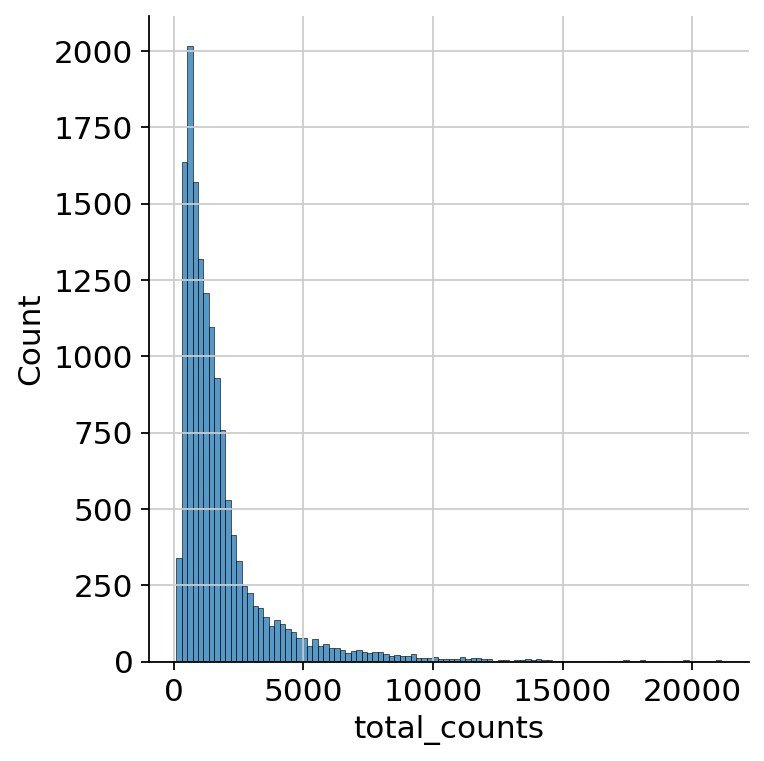

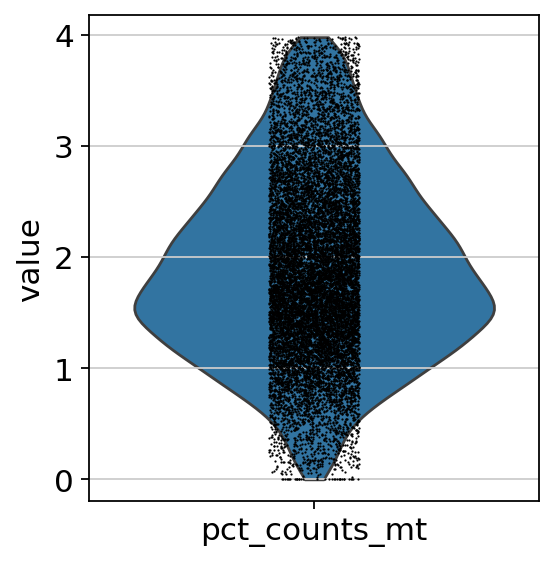

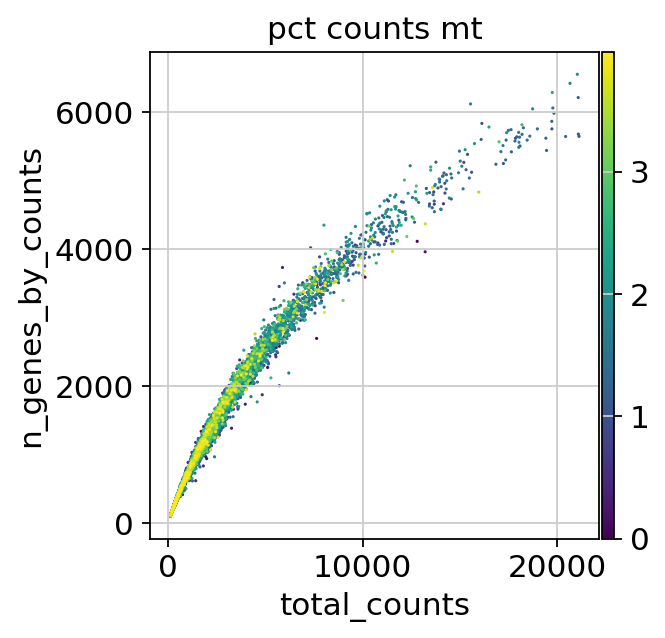

AnnData object with n_obs × n_vars = 14814 × 36601
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'outlier', 'mt_outlier'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'

In [11]:
p1 = sns.displot(adata.obs["total_counts"], bins=100, kde=False)
# sc.pl.violin(adata, 'total_counts')
p2 = sc.pl.violin(adata, "pct_counts_mt")
p3 = sc.pl.scatter(adata, "total_counts", "n_genes_by_counts", color="pct_counts_mt")
adata

From these distributions you choose gentle thresholds that remove only the most obvious low quality cells and uninformative genes, for example cells with very few detected genes or extremely low or high total counts, and genes that are not expressed in any or in only a few cells. Keep the filtering mild so that you do not accidentally remove biologically meaningful or rare cell populations.

In [12]:
sc.pp.filter_cells(adata, min_genes=100)
sc.pp.filter_genes(adata, min_cells=3)
adata

AnnData object with n_obs × n_vars = 14813 × 28471
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'outlier', 'mt_outlier', 'n_genes'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'



Cells with fewer than 100 detected genes were removed from the dataset.
Genes that were expressed in fewer than three cells were also excluded.


# **3.3 Doublet Detection**
Doublets arise when two cells are captured under the same barcode (for example in the same droplet). Doublets formed from the same cell type are called homotypic and are often difficult to detect from the count matrix alone, so they are usually considered less problematic. In contrast, doublets formed from different cell types or states (heterotypic doublets) are more critical, because they are likely to be misclassified and can distort downstream analyses. Therefore, doublet detection and removal are typically performed as an early preprocessing step. Doublets can be identified based on unusually high counts and numbers of detected features, or by generating artificial doublets and comparing them with observed cells. 


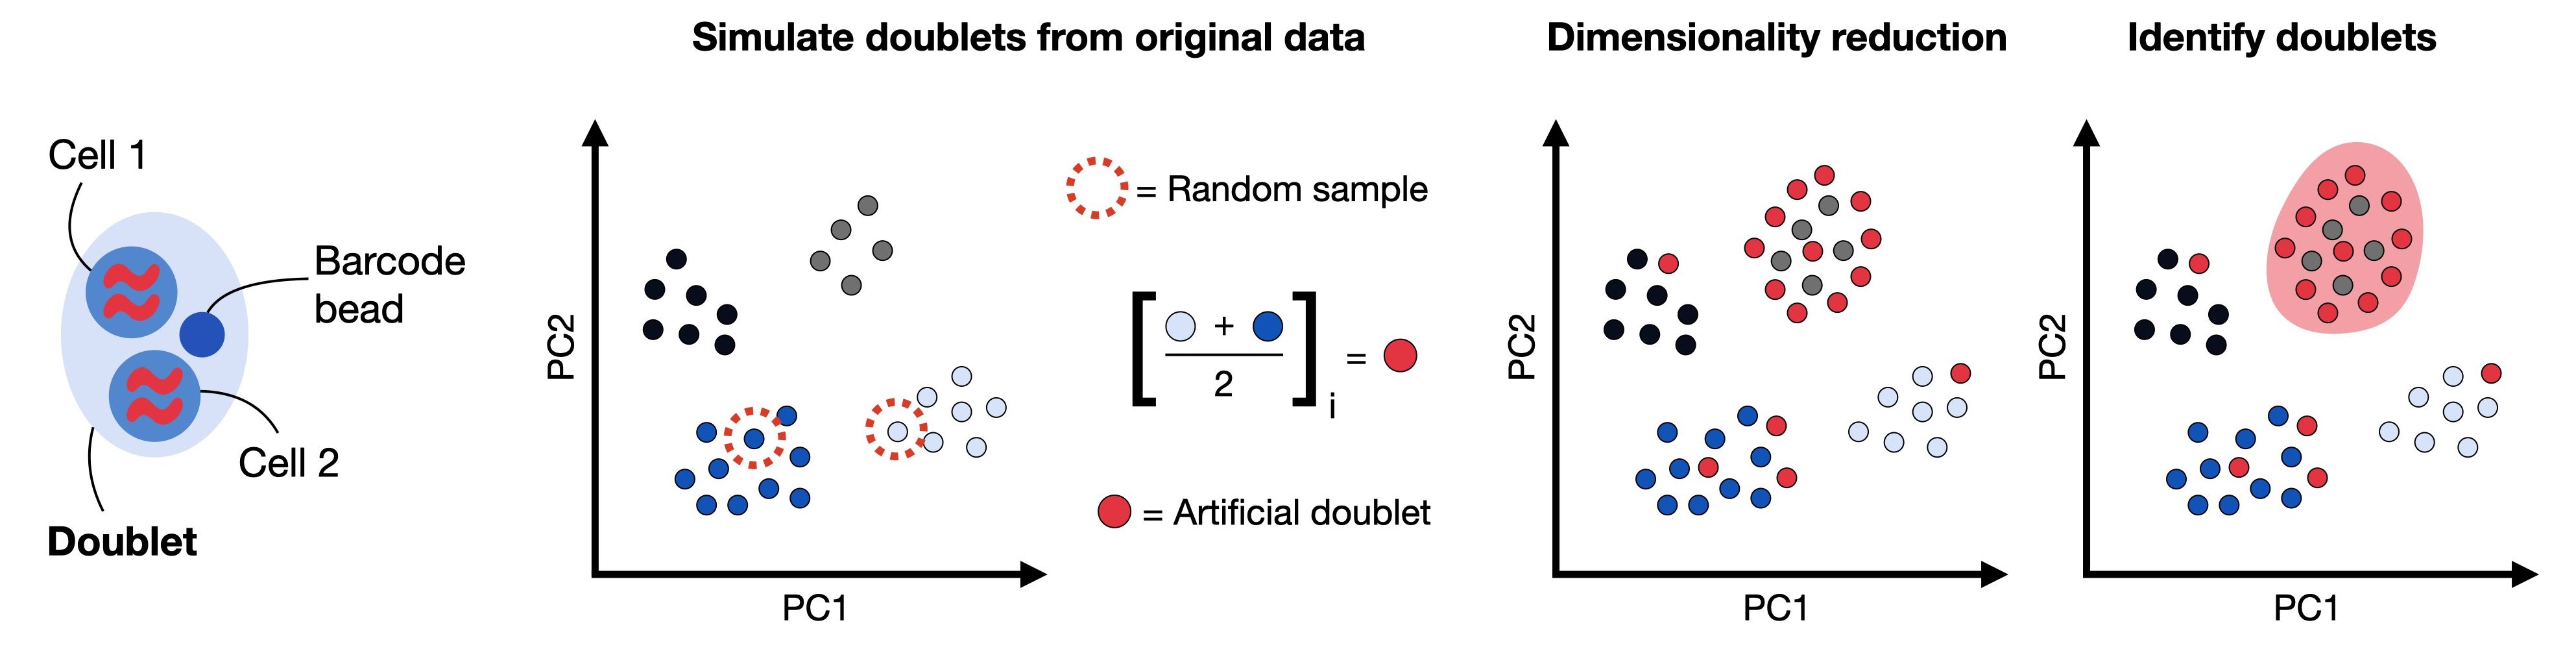

In this analysis we use Scrublet, which predicts doublets by simulating artificial doublets and applying a nearest-neighbor classifier to compare these with the observed transcriptomes. The Scanpy function scanpy.pp.scrublet() adds a doublet_score and a predicted_doublet flag to .obs. Doublets can then be removed either by directly excluding cells labeled as predicted doublets, or by performing clustering first and filtering out clusters with high average doublet scores.

In [13]:
sc.pp.scrublet(adata)

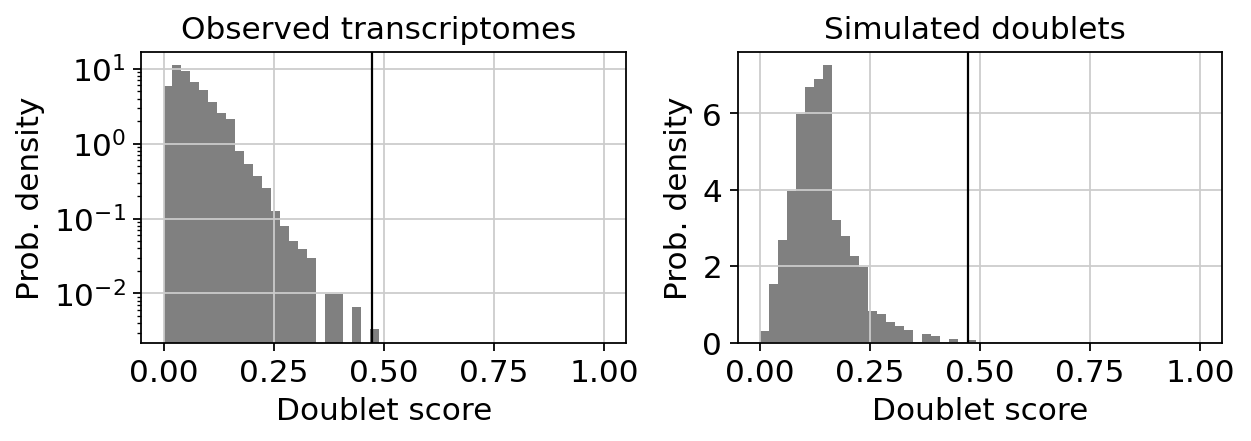

In [14]:
sc.pl.scrublet_score_distribution(adata)

# **4. Normalizaton**
The next preprocessing step is normalization. A common approach is count depth scaling with subsequent log plus one (log1p) transformation. Count depth scaling normalizes the data to a “size factor” such as the median count depth in the dataset, ten thousand (CP10k) or one million (CPM, counts per million). The size factor for count depth scaling can be controlled via `target_sum` in `pp.normalize_total`. We are applying median count depth normalization with log1p transformation (AKA log1PF).

In [15]:
# Saving count data
adata.layers["counts"] = adata.X.copy()
# Normalizing to median total counts
sc.pp.normalize_total(adata)
# Logarithmize the data
sc.pp.log1p(adata)

# **5. Feature Selection**
As a next step, we want to reduce the dimensionality of the dataset and only include the most informative genes. This step is commonly known as feature selection.

In [16]:
sc.pp.highly_variable_genes(adata, n_top_genes=2000)

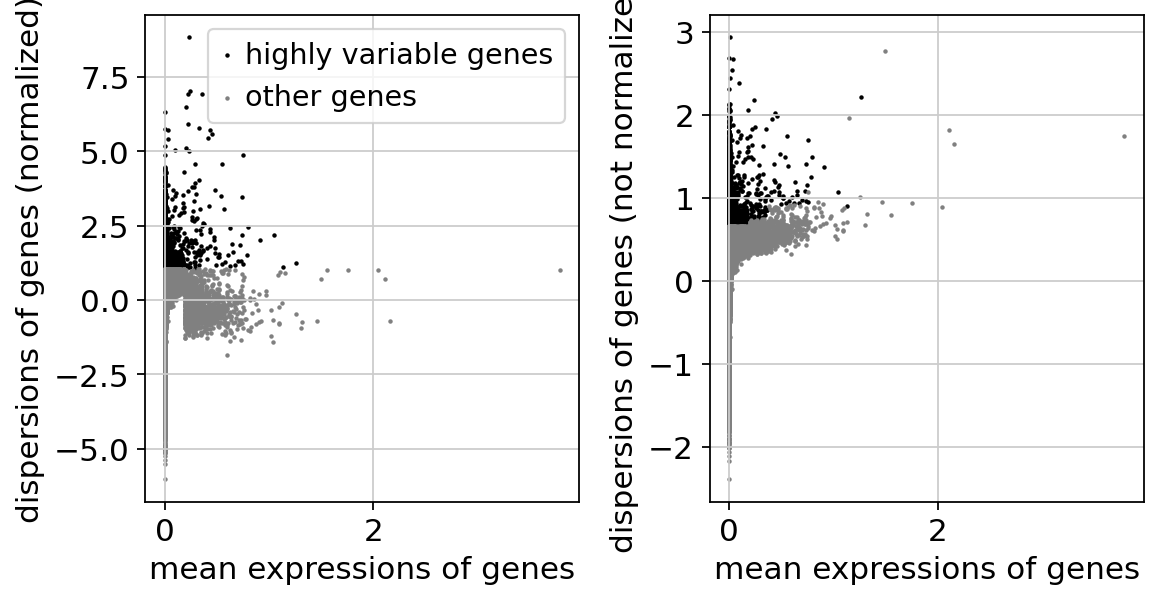

In [17]:
sc.pl.highly_variable_genes(adata)

# **6. Dimensionality Reduction**
Reduce the dimensionality of the data by running principal component analysis (PCA), which reveals the main axes of variation and denoises the data.

In [18]:
sc.tl.pca(adata)

Let us inspect the contribution of single PCs to the total variance in the data. This gives us information about how many PCs we should consider in order to compute the neighborhood relations of cells, e.g. used in the clustering function leiden() or tsne(). In our experience, there does not seem to be signifigant downside to overestimating the numer of principal components.

Let us inspect the contribution of single PCs to the total variance in the data. This gives us information about how many PCs we should consider in order to compute the neighborhood relations of cells, e.g. used in the clustering function `leiden()` or `tsne()`. In our experience, there does not seem to be signifigant downside to overestimating the numer of principal components.

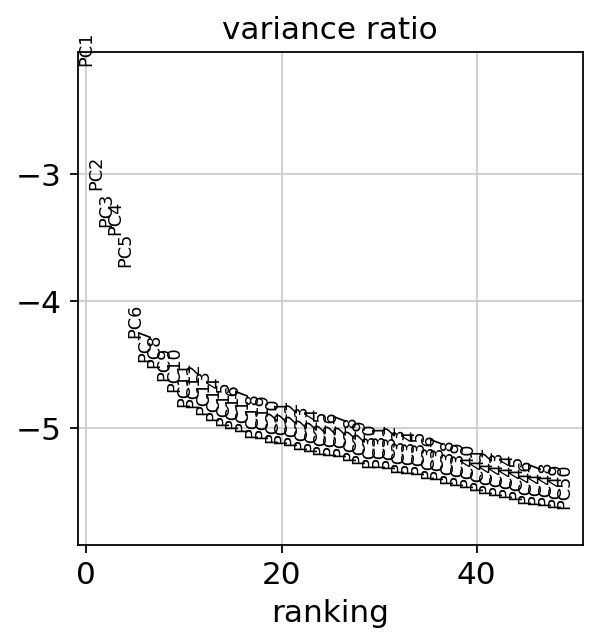

In [19]:
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)

You can also plot the principal components to see if there are any potentially undesired features (e.g. batch, QC metrics) driving signifigant variation in this dataset. In this case, there isn’t anything too alarming, but it’s a good idea to explore this.

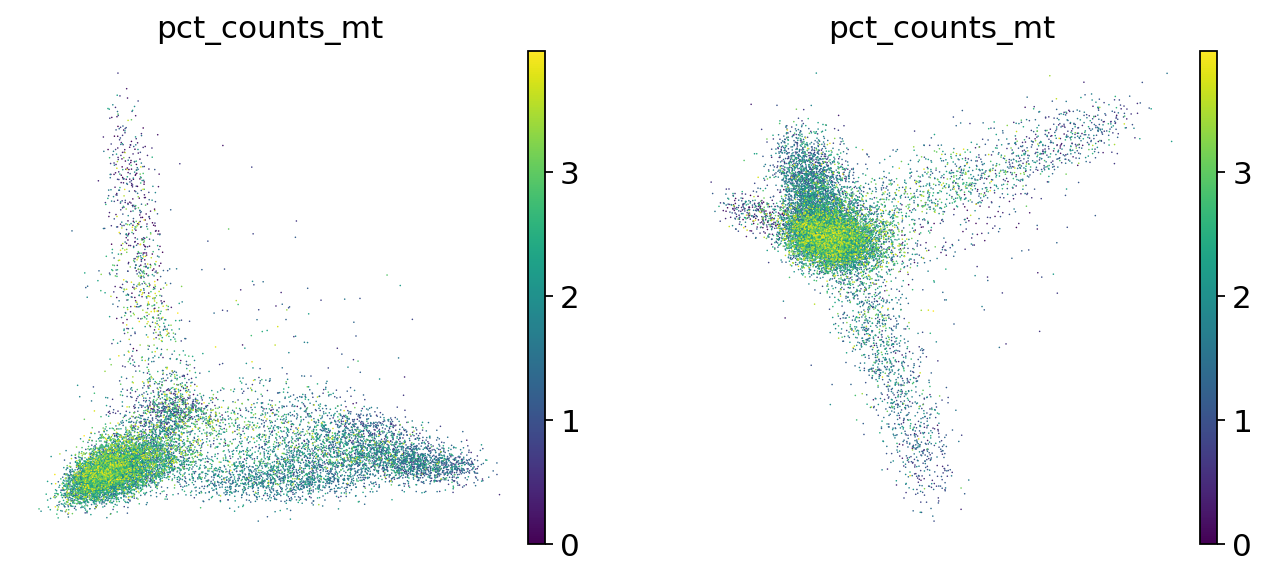

In [20]:
sc.pl.pca(
    adata,
    color=["pct_counts_mt", "pct_counts_mt"],
    dimensions=[(0, 1), (2, 3)],
    ncols=2,
    size=2,
)

# **7. Nearest Neighbor Graph Construction and Visualization**
Let us compute the neighborhood graph of cells using the PCA representation of the data matrix.

In [21]:
sc.pp.neighbors(adata)

This graph can then be embedded in two dimensions for visualiztion with UMAP[[McInnes et al., 2018](https://arxiv.org/abs/1802.03426)]

In [22]:
sc.tl.umap(adata)

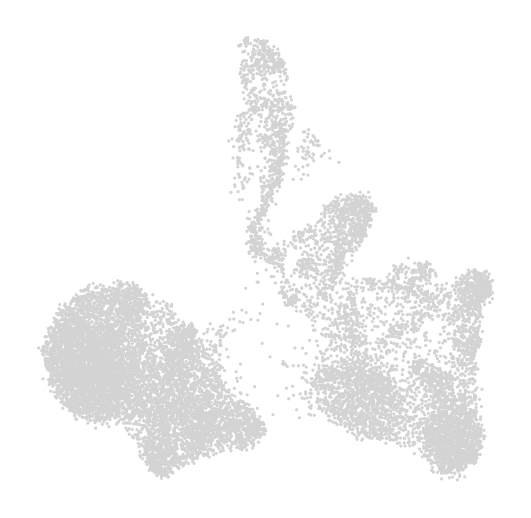

In [23]:
sc.pl.umap(adata)

# **8. Clustering**
As with Seurat and many other frameworks, we recommend the Leiden graph-clustering method (community detection based on optimizing modularity) [[Traag et al., 2019](https://www.nature.com/articles/s41598-019-41695-z)]. Note that Leiden clustering directly clusters the neighborhood graph of cells, which we already computed in the previous section.

In [24]:
# Using the igraph implementation and a fixed number of iterations can be significantly faster,
# especially for larger datasets
sc.tl.leiden(adata, flavor="igraph", n_iterations=2)

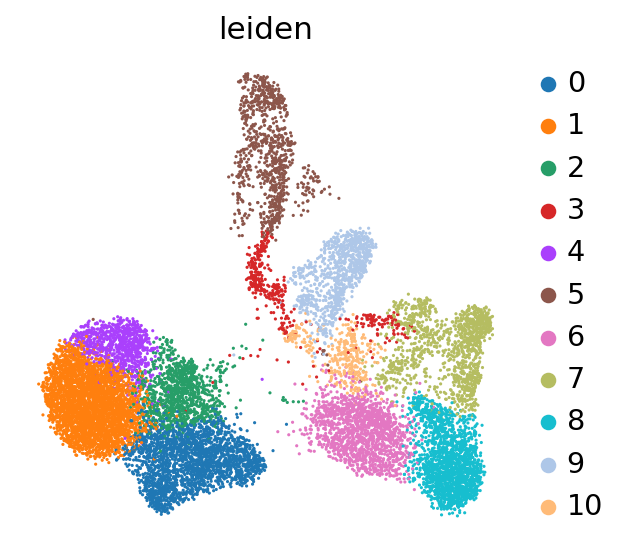

In [25]:
sc.pl.umap(adata, color=["leiden"])

# **9. Re-assess quality control and cell filtering**
As indicated before, we will now re-assess our filtering strategy by visualizing different QC metrics using UMAP.

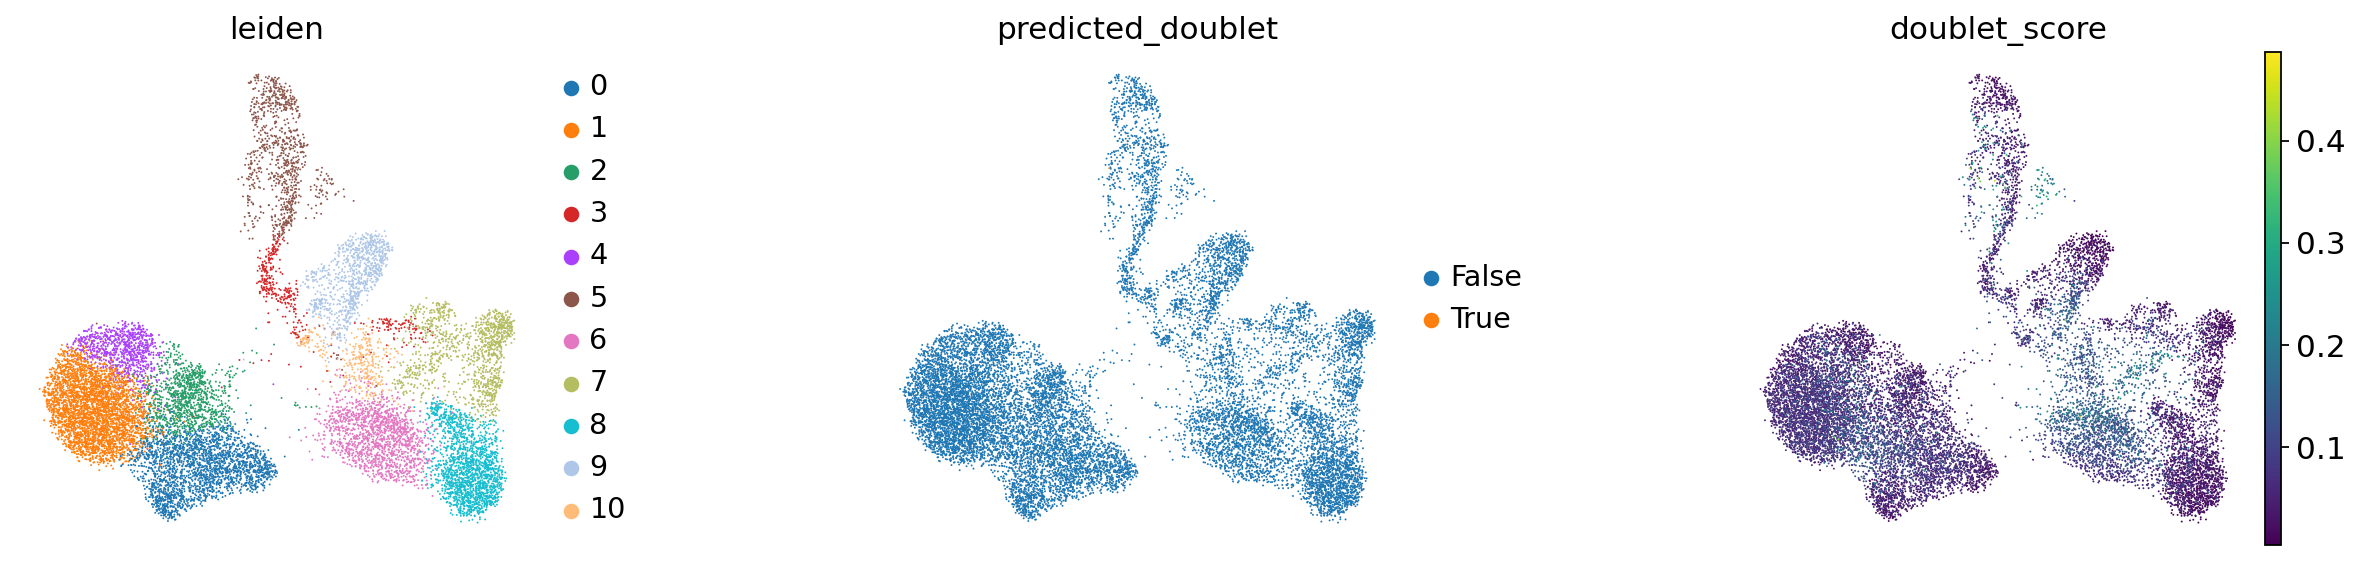

In [26]:
sc.pl.umap(
    adata,
    color=["leiden", "predicted_doublet", "doublet_score"],
    # increase horizontal space between panels
    wspace=0.5,
    size=3,
)

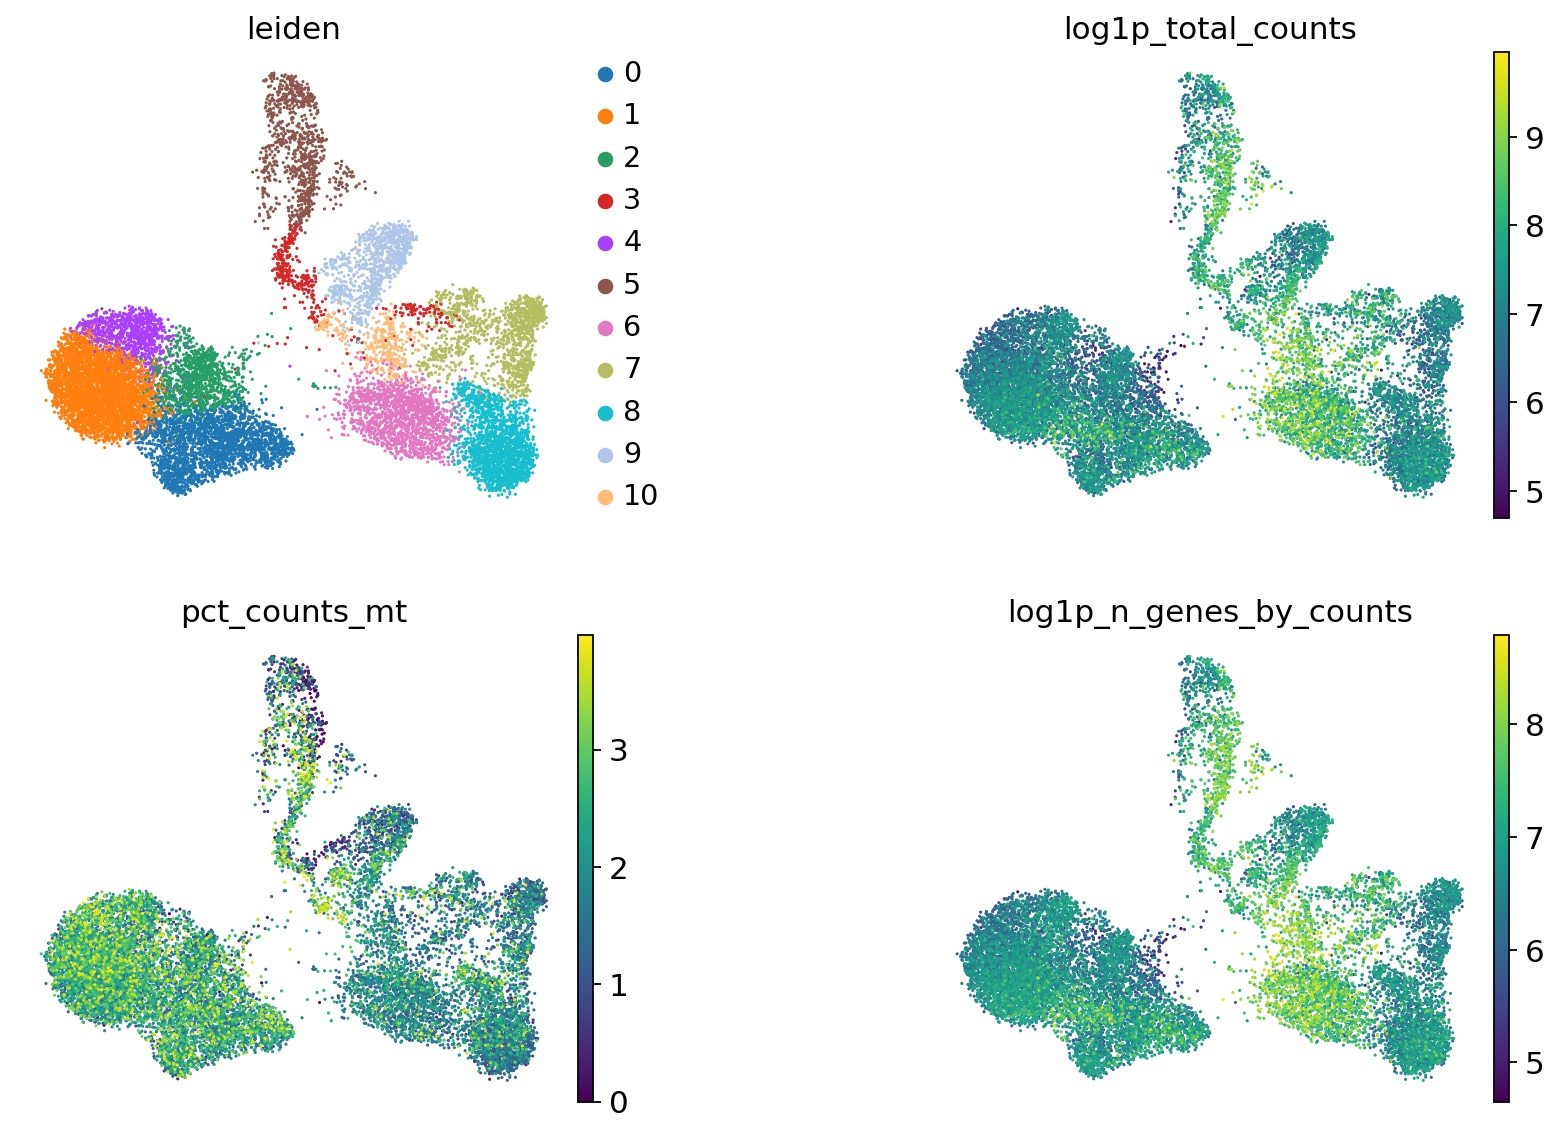

In [27]:
sc.pl.umap(
    adata,
    color=["leiden", "log1p_total_counts", "pct_counts_mt", "log1p_n_genes_by_counts"],
    wspace=0.5,
    ncols=2,
)

In [28]:
for res in [0.02, 0.5, 1.0]:
    sc.tl.leiden(adata, key_added=f"leiden_res_{res:4.2f}", resolution=res, flavor="igraph")

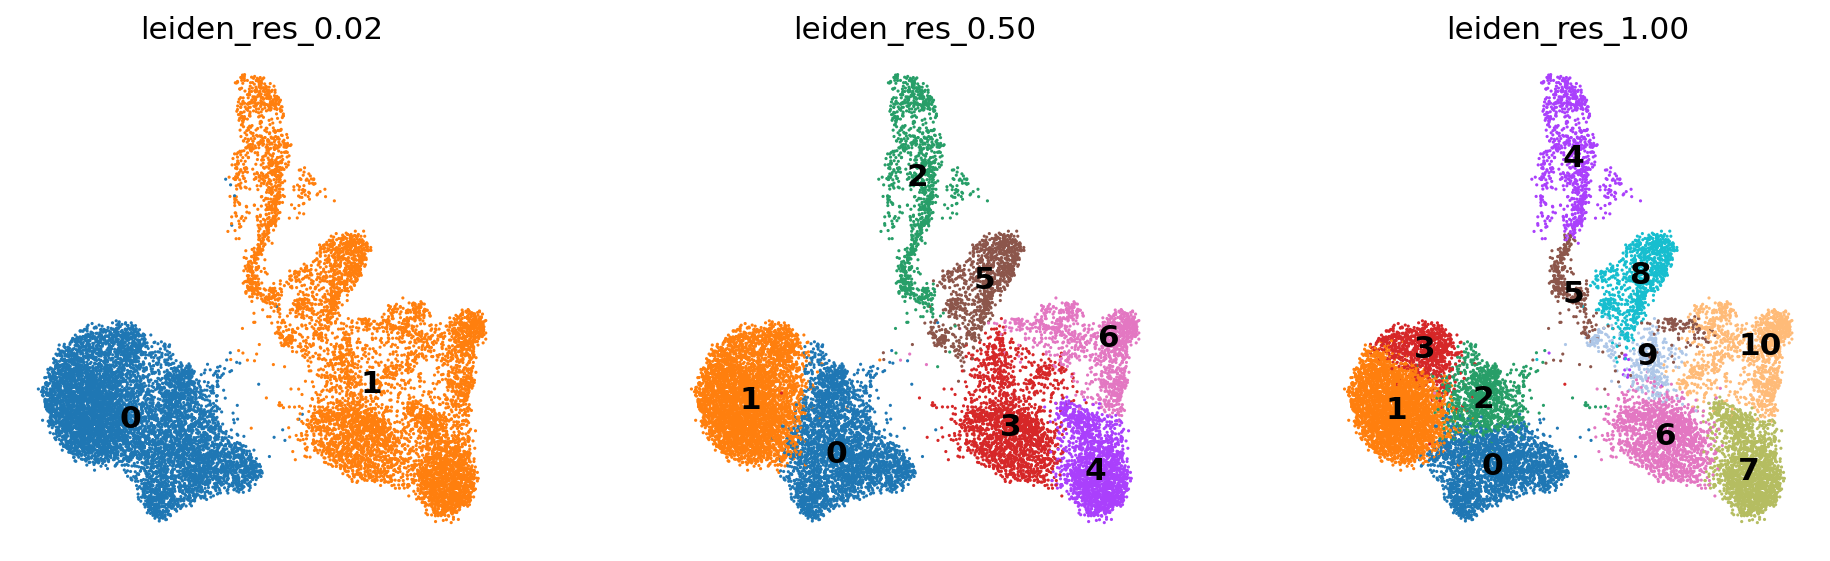

In [29]:
sc.pl.umap(
    adata,
    color=["leiden_res_0.02", "leiden_res_0.50", "leiden_res_1.00"],
    legend_loc="on data",
)

# **Differentially-expressed Genes as Markers**
WE can calculate marker genes per cluster and then look up whether we can link those marker genes to any known biology, such as cell types and/or states. This is typically done using simple statistical tests, such as Wilcoxon and t-test, for each cluster vs the rest.

In [30]:
# Obtain cluster-specific differentially expressed genes
sc.tl.rank_genes_groups(adata, groupby="leiden_res_0.50", method="wilcoxon")

We can then visualize the top 10 differentially-expressed genes on a dotplot.

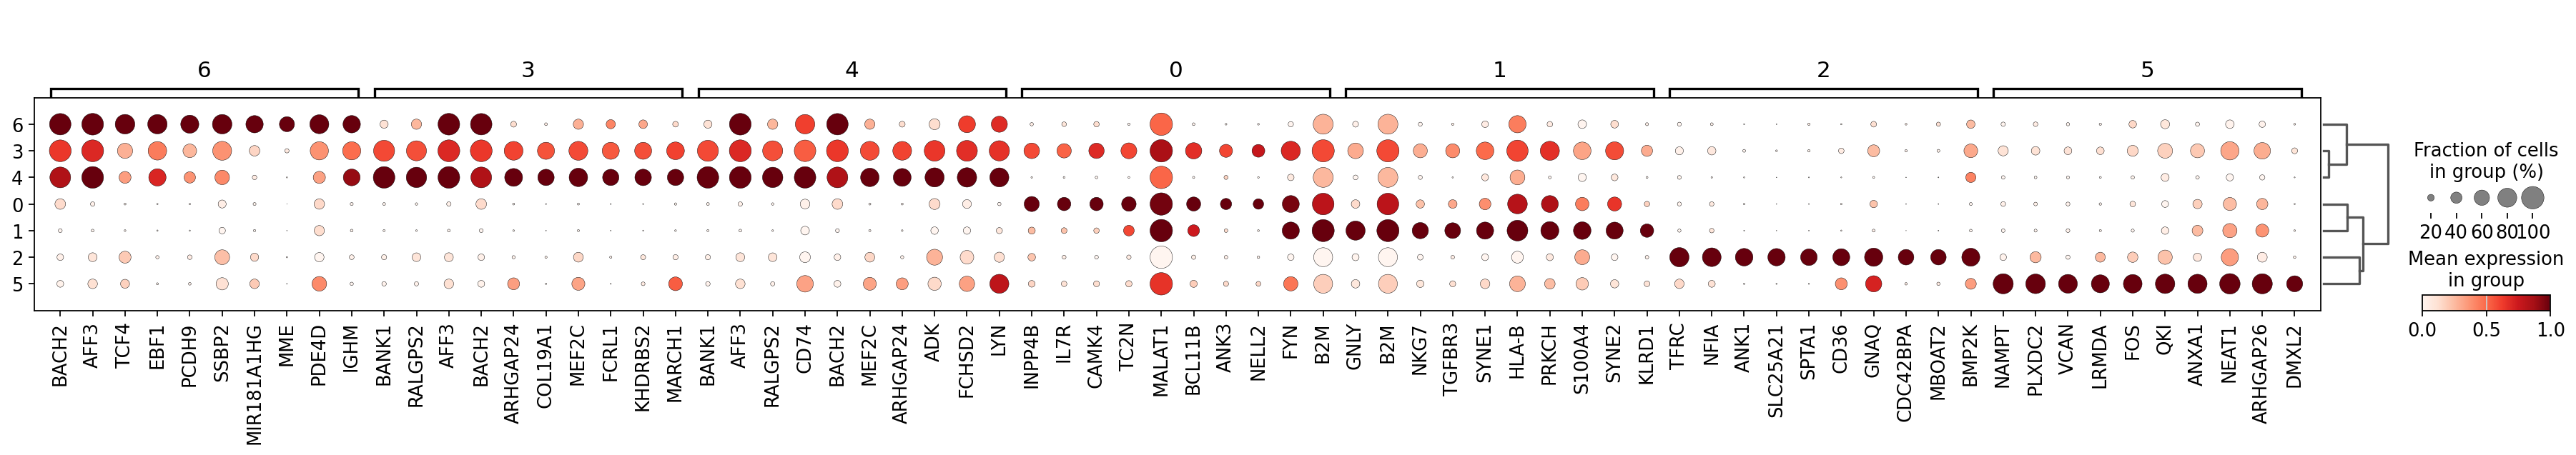

In [31]:
sc.pl.rank_genes_groups_dotplot(adata, groupby="leiden_res_0.50", standard_scale="var", n_genes=10)

In [32]:
sc.get.rank_genes_groups_df(adata, group="2").head(10)

,names,scores,logfoldchanges,pvals,pvals_adj
0,TFRC,43.128525,4.570836,0.000000e+00,0.000000e+00
1,NFIA,40.831535,4.286628,0.000000e+00,0.000000e+00
2,ANK1,40.103790,6.407094,0.000000e+00,0.000000e+00
3,SLC25A21,40.038624,8.138275,0.000000e+00,0.000000e+00
4,SPTA1,37.279022,6.628173,3.590035e-304,1.277649e-300
5,CD36,36.874443,4.901449,1.187049e-297,3.755163e-294
6,GNAQ,34.970467,2.854386,6.327419e-268,1.637709e-264
7,CDC42BPA,34.246910,6.302514,4.848597e-257,1.150370e-253
8,MBOAT2,33.372944,5.361129,3.386132e-244,6.886183e-241
9,BMP2K,33.313354,2.709808,2.473739e-243,4.695322e-240


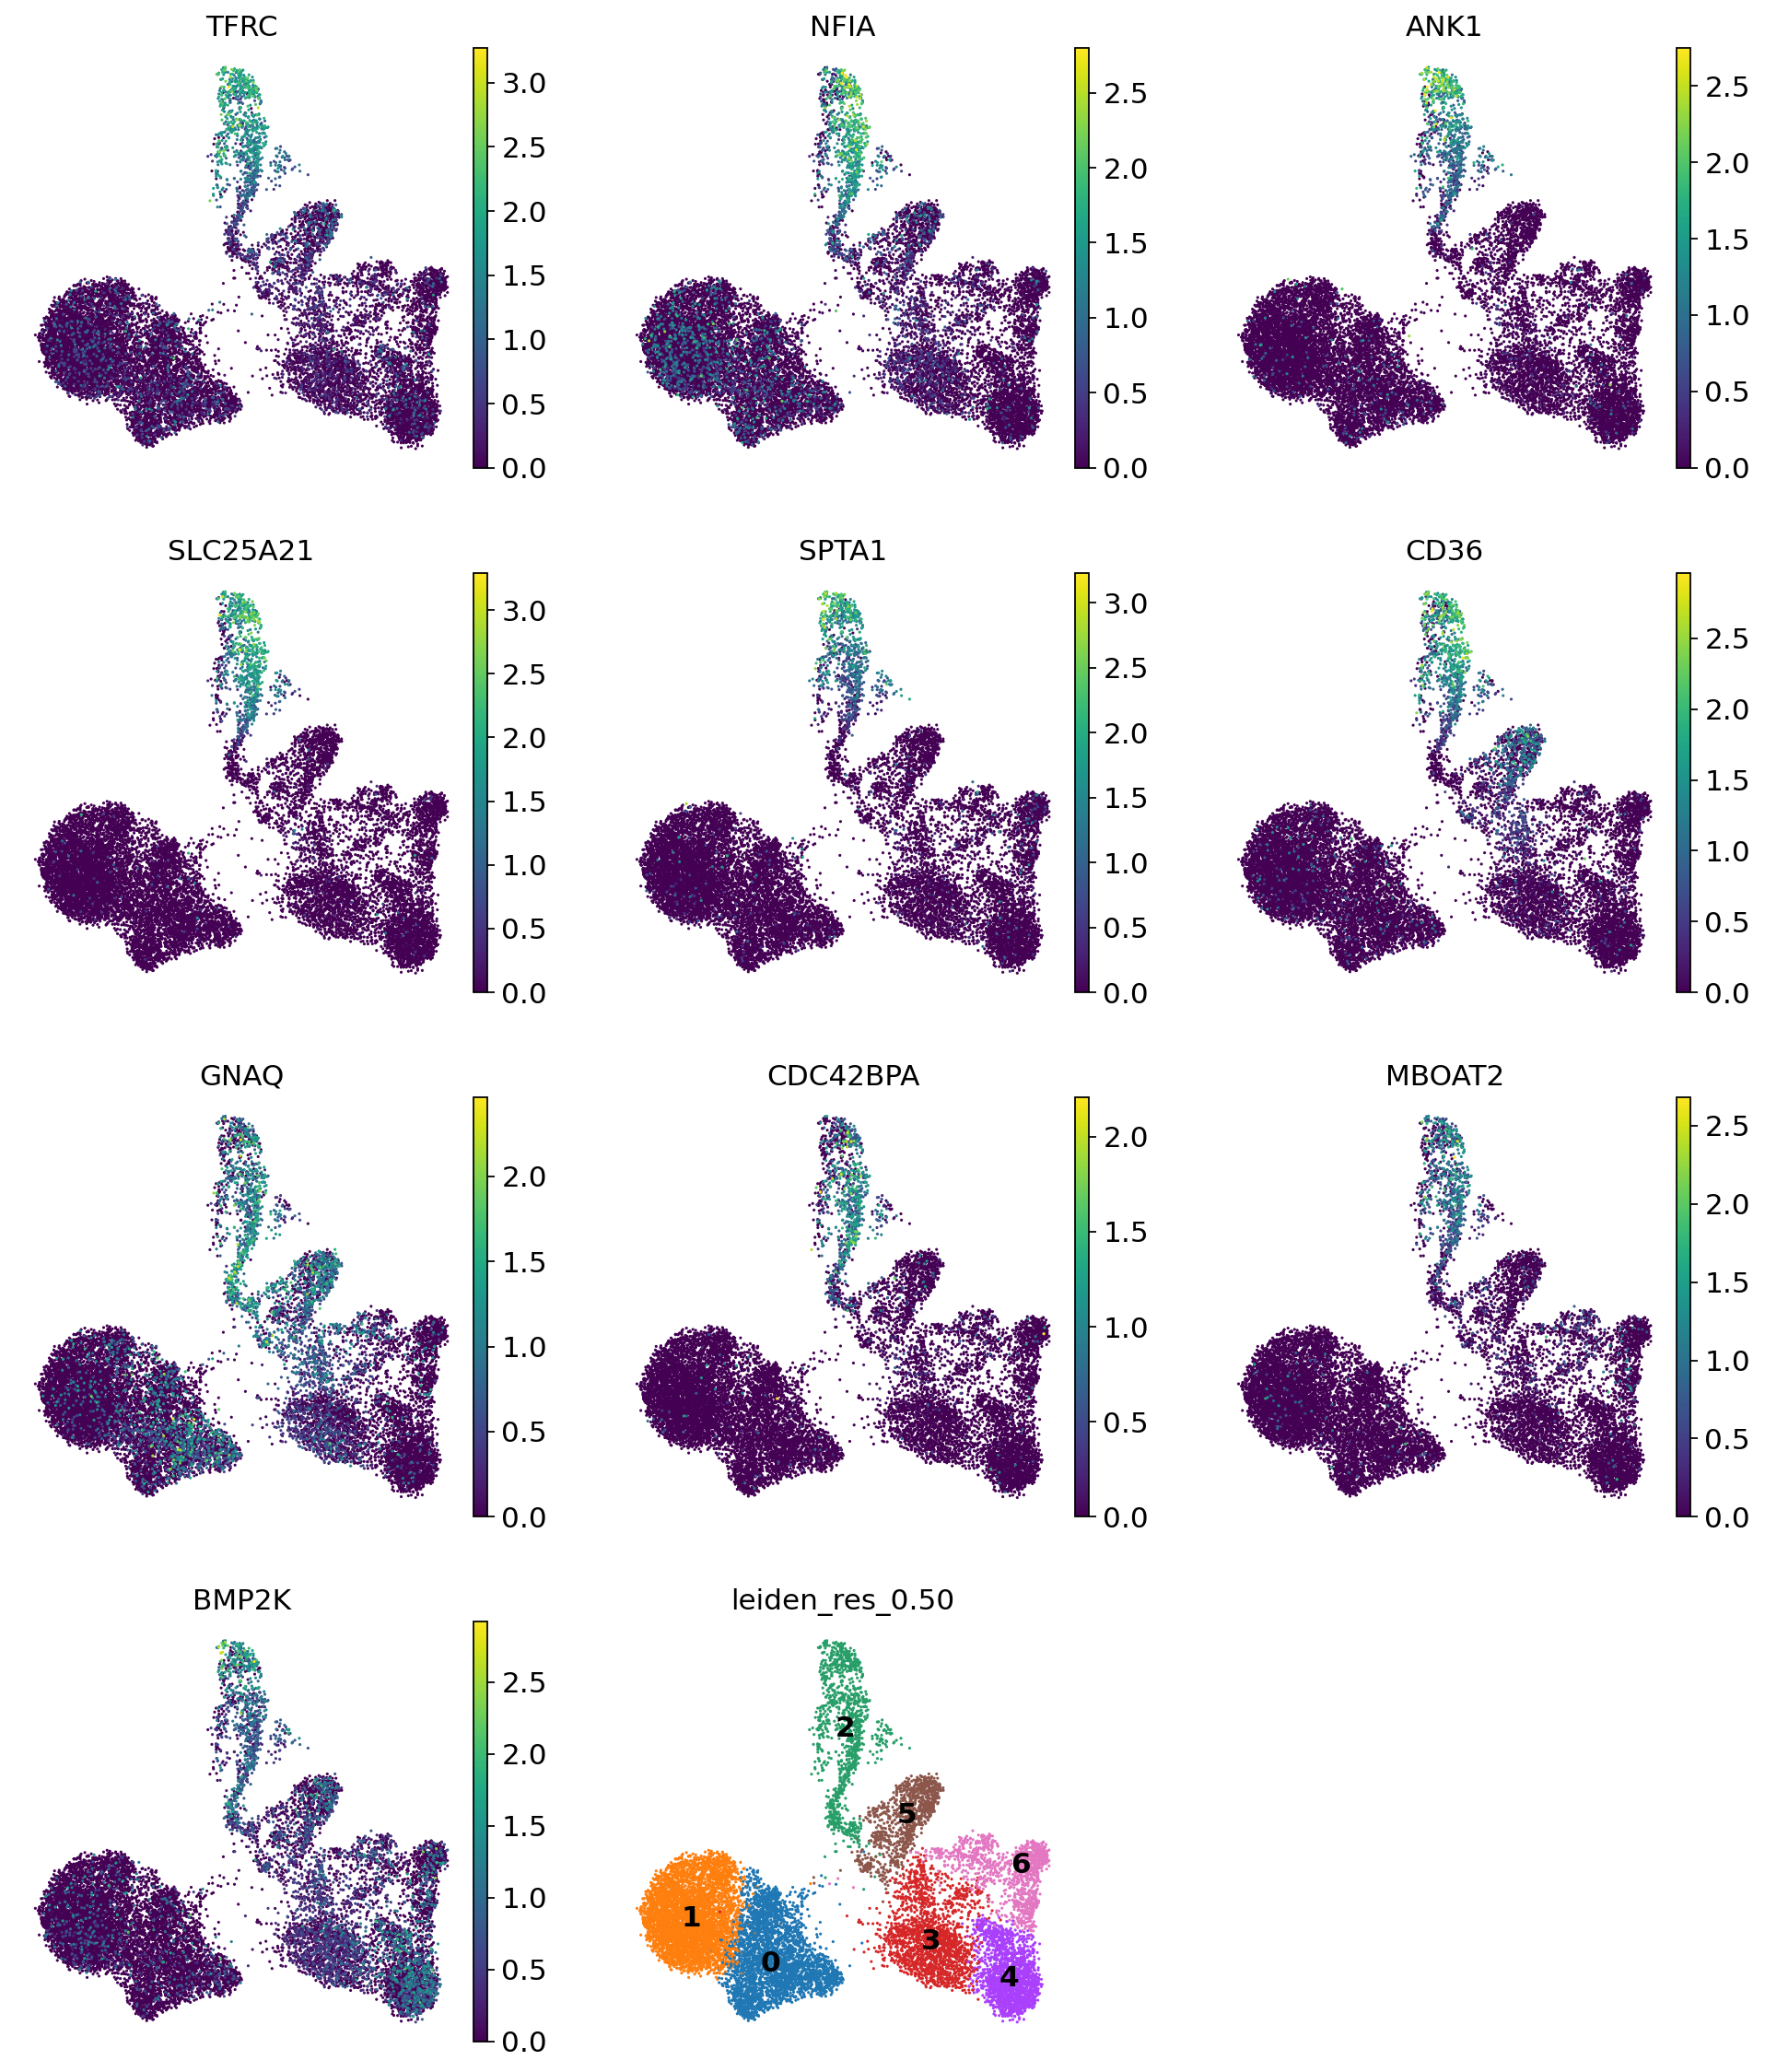

In [33]:
dc_cluster_genes = sc.get.rank_genes_groups_df(adata, group="2").head(10)["names"]
sc.pl.umap(
    adata,
    color=[*dc_cluster_genes, "leiden_res_0.50"],
    legend_loc="on data",
    frameon=False,
    ncols=3,
)

Based on marker genes in each cluster, we can identify each cell type.
Here we are sharing one possible way to annotate each cluster.

Step 1. Get marker genes in each cluster.

Step 2. Find cell type that is highly associated with the provided marker genes via third-party tools, such as [Enrichr](https://maayanlab.cloud/Enrichr/).

In [34]:
df = sc.get.rank_genes_groups_df(adata, group="2")

names_str = ", ".join(df["names"].head(10).astype(str).tolist())

print(names_str)


TFRC, NFIA, ANK1, SLC25A21, SPTA1, CD36, GNAQ, CDC42BPA, MBOAT2, BMP2K


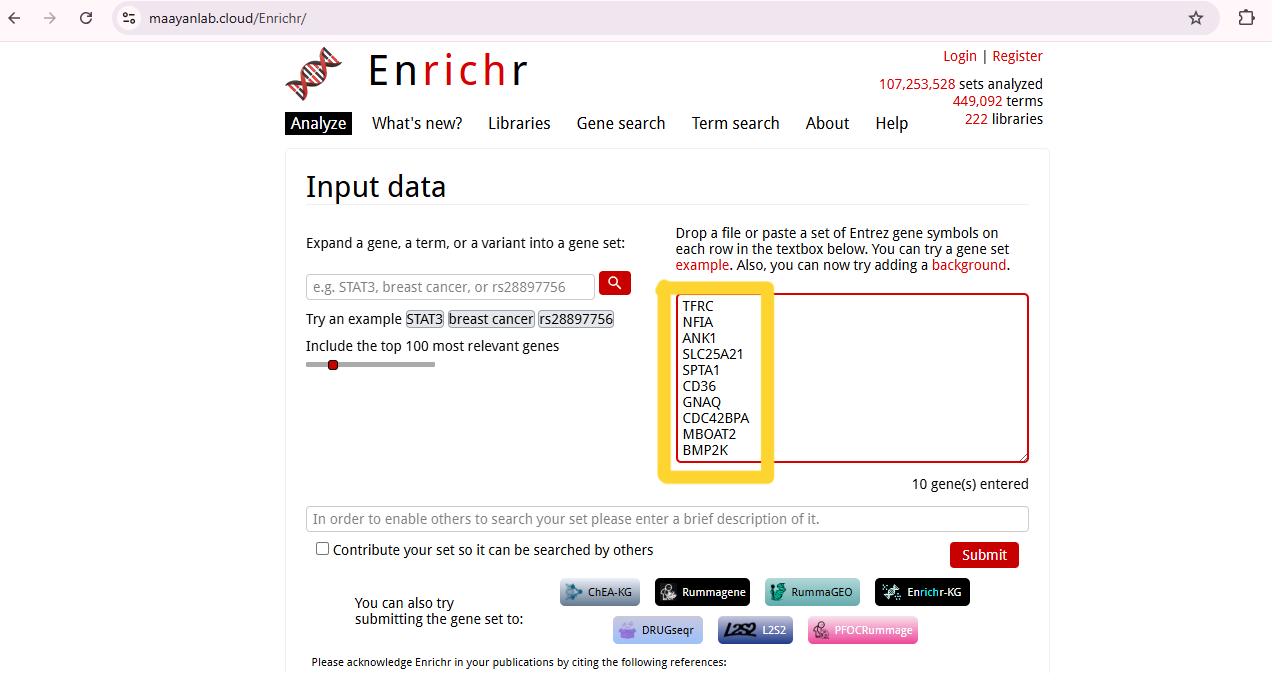

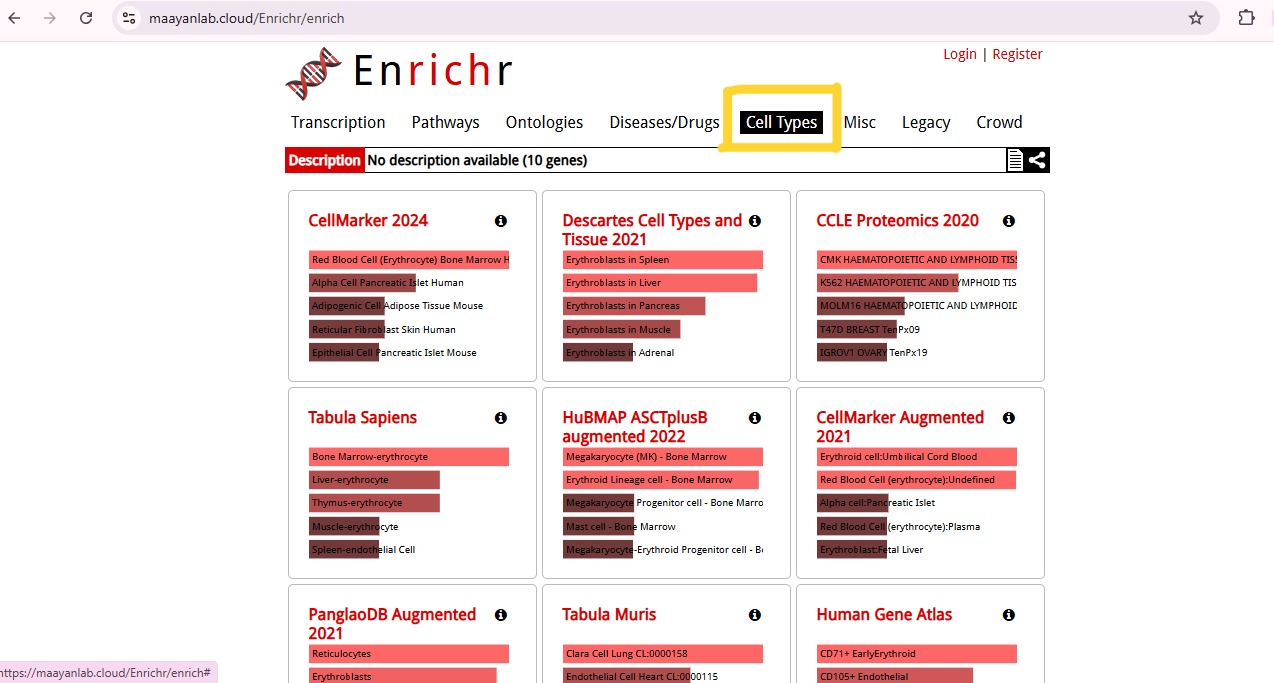

In [35]:
cluster_to_name = {
    "0": "CD8+ T",
    "1": "CD4+ T",
    "2": "Erythroid",
    "3": "B cells",
    "4": "B cells",
    "5": "Monocytes",
    "6": "B cells",
}

adata.obs["celltype"] = (
    adata.obs["leiden_res_0.50"].map(cluster_to_name).astype("category")
)

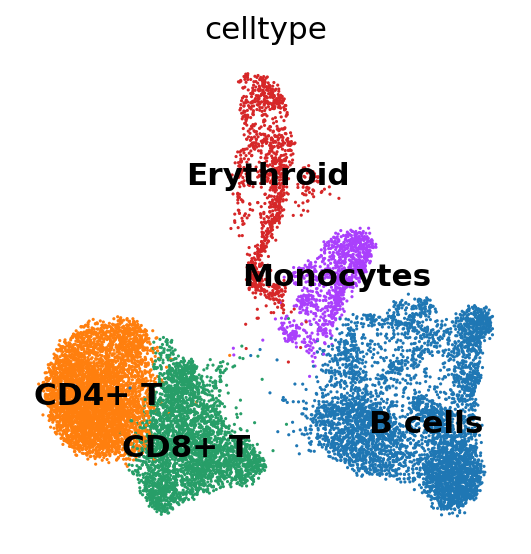

In [36]:
sc.pl.umap(adata, color="celltype", legend_loc="on data")


You may have noticed that the p-values found here are extremely low. This is due to the statistical test being performed considering each cell as an independent sample. For a more conservative approach you may want to use a more powerful differential expression tool, like [PyDESeq2](https://pydeseq2.readthedocs.io/en/stable/).